Ran LU - Paris Saclay M2 AI - ran.lu@universite-paris-saclay.fr

# Task 2 - IIR delay effect

This notebook applies the feedback delay
\[
s[t] = \alpha e[t] + \beta s[t-D]
\]
to `data/music.wav`. It measures the impulse and frequency responses, tests stability, studies the parameters, and compares the result with the FIR delay from Task 1.

## Setup and real audio input

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Audio, display
from scipy.io import wavfile

plt.style.use("seaborn-v0_8-whitegrid")

AUDIO_PATH = Path("data/music.wav")
sample_rate, samples = wavfile.read(AUDIO_PATH)
if samples.ndim == 2:
    samples = samples.mean(axis=1)
if np.issubdtype(samples.dtype, np.integer):
    scale = max(abs(np.iinfo(samples.dtype).min), np.iinfo(samples.dtype).max)
    audio = samples.astype(np.float64) / scale
else:
    audio = samples.astype(np.float64)
audio -= audio.mean()

time = np.arange(len(audio)) / sample_rate
alpha = 0.8
beta = 0.55
delay_seconds = 0.18
delay_samples = int(round(delay_seconds * sample_rate))

input_summary = pd.DataFrame({
    "File": [str(AUDIO_PATH)],
    "Sample rate (Hz)": [sample_rate],
    "Samples": [len(audio)],
    "Duration (s)": [len(audio) / sample_rate],
    "RMS": [np.sqrt(np.mean(audio**2))],
    "Peak magnitude": [np.max(np.abs(audio))],
})
display(input_summary.round(4))
display(Audio(audio, rate=sample_rate, normalize=False))

,File,Sample rate (Hz),Samples,Duration (s),RMS,Peak magnitude
0,data/music.wav,16000,140001,8.7501,0.2293,0.9736


### Result analysis

The selected input is the same 8.7501-second, 16 kHz mono `music.wav` used in Task 1, allowing the filter architectures to be compared on identical content. Its DC-removed RMS is 0.2293 and its peak magnitude is 0.9736. The IIR parameters are (\alpha=0.8), (\beta=0.55), and (D=2880) samples (0.18 s); because (|\beta|<1), the echo train should decay.

### Code analysis

The loading and normalization path matches Task 1 exactly. All filter parameters are declared once, and the delay is derived from the WAV file's sample rate rather than assuming a fixed rate. This prevents a change of playback speed or echo time if another WAV file is substituted.

## 1. Time-domain IIR implementation

In [2]:
def iir_delay(input_signal, input_scale, feedback, delay):
    """Apply y[n] = input_scale*x[n] + feedback*y[n-delay]."""
    if delay < 1:
        raise ValueError("delay must be at least one sample")
    output = np.zeros_like(input_signal, dtype=float)
    for n, sample in enumerate(input_signal):
        output[n] = input_scale * sample
        if n >= delay:
            output[n] += feedback * output[n - delay]
    return output


iir_output = iir_delay(audio, alpha, beta, delay_samples)


,Signal,RMS,Peak magnitude
0,Input,0.2293,0.9736
1,IIR output,0.2145,0.9553


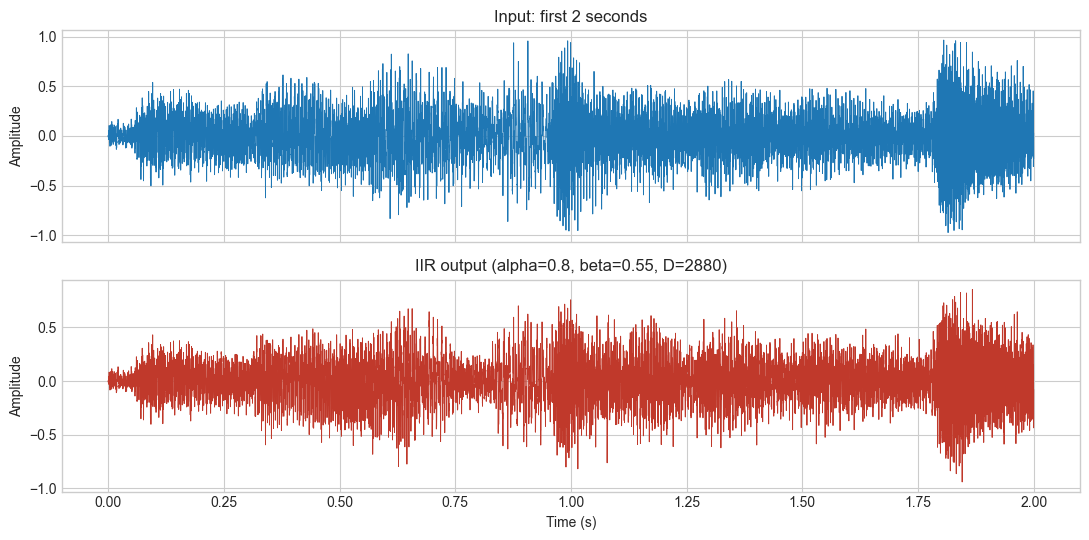

In [3]:
input_rms = np.sqrt(np.mean(audio**2))
output_rms = np.sqrt(np.mean(iir_output**2))
iir_metrics = pd.DataFrame({
    "Signal": ["Input", "IIR output"],
    "RMS": [input_rms, output_rms],
    "Peak magnitude": [np.max(np.abs(audio)), np.max(np.abs(iir_output))],
})
display(iir_metrics.round(4))

view_end = int(2.0 * sample_rate)
fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
axes[0].plot(time[:view_end], audio[:view_end], lw=0.65)
axes[0].set(title="Input: first 2 seconds", ylabel="Amplitude")
axes[1].plot(time[:view_end], iir_output[:view_end], lw=0.65, color="#c0392b")
axes[1].set(
    title=f"IIR output (alpha={alpha}, beta={beta}, D={delay_samples})",
    xlabel="Time (s)",
    ylabel="Amplitude",
)
fig.tight_layout()
plt.show()
display(Audio(iir_output, rate=sample_rate, normalize=False))

### Result analysis

After 0.18 s, feedback mixes each output segment into the next delay period, producing repeated decaying echoes over the continuous music. The output RMS is 0.2145, 0.58 dB below the input RMS, and its peak magnitude is 0.9553. Although feedback adds delayed energy, the direct path is first scaled by (\alpha=0.8); for this recording and parameter set, that reduction is larger than the feedback energy increase.

### Code analysis

The delayed sample is read from the already computed `output`, which implements feedback under zero initial conditions. Metrics are measured on the raw result, and playback does not normalize because the peak remains below one. The two-second view contains more than eleven delay periods and makes the accumulated waveform change visible.

## 2. Numerical impulse response

,Echo number,Sample,Measured h[n]
0,0,0,0.800000
1,1,2880,0.440000
2,2,5760,0.242000
3,3,8640,0.133100
4,4,11520,0.073205
5,5,14400,0.040263
6,6,17280,0.022145
7,7,20160,0.012179
8,8,23040,0.006699


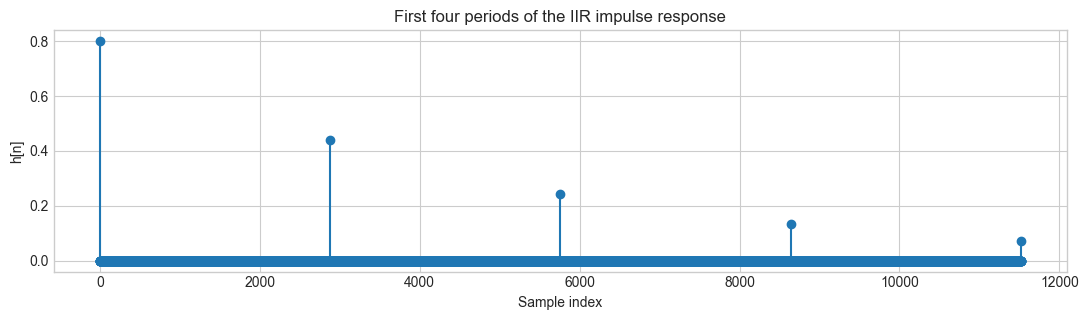

In [4]:
impulse_length = 8 * delay_samples + 1
unit_impulse = np.zeros(impulse_length)
unit_impulse[0] = 1.0
impulse_response = iir_delay(unit_impulse, alpha, beta, delay_samples)
echo_indices = np.arange(0, impulse_length, delay_samples)
echo_values = impulse_response[echo_indices]
echo_table = pd.DataFrame({"Echo number": np.arange(len(echo_indices)), "Sample": echo_indices, "Measured h[n]": echo_values})
display(echo_table.round(6))

fig, ax = plt.subplots(figsize=(11, 3.3))
ax.stem(np.arange(4 * delay_samples + 1), impulse_response[: 4 * delay_samples + 1], basefmt=" ")
ax.set(title="First four periods of the IIR impulse response", xlabel="Sample index", ylabel="h[n]")
fig.tight_layout()
plt.show()


### Result analysis

Non-zero impulse samples occur at (0,D,2D,\ldots). The measured amplitudes begin 0.8, 0.44, 0.242, and 0.1331, following (h[kD]=\alpha\beta^k). At the eighth echo the amplitude is 0.006699: the response is theoretically infinite, but it decays rapidly for (\beta=0.55).

### Code analysis

The input impulse spans eight delay intervals, and the response is sampled exactly at multiples of `delay_samples`. This compact table exposes the recursive geometric sequence without relying only on the stem plot. The same `iir_delay` function processes both the impulse and the WAV file.

## 3. Numerical frequency response

,Minimum magnitude (dB),Maximum magnitude (dB),Resonance spacing (Hz)
0,-5.7145,4.9575,5.5556


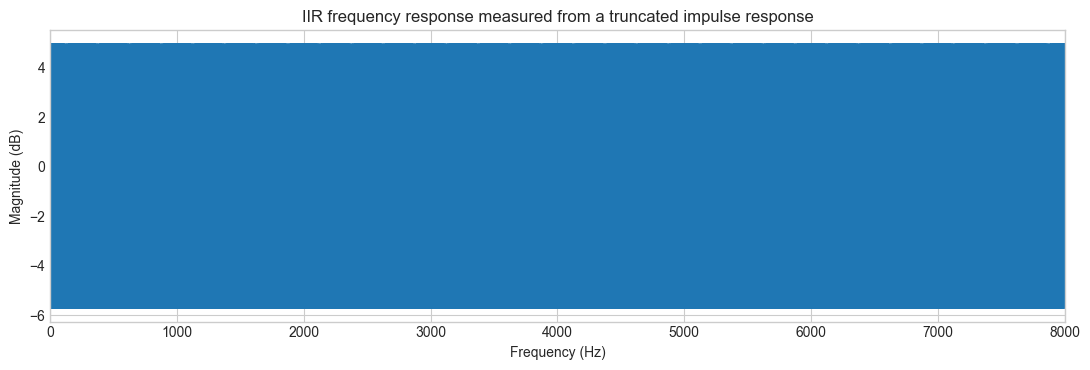

In [5]:
fft_size = 2**18
frequencies = np.fft.rfftfreq(fft_size, 1 / sample_rate)
frequency_response = np.fft.rfft(impulse_response, n=fft_size)
magnitude = np.abs(frequency_response)
magnitude_db = 20 * np.log10(np.maximum(magnitude, 1e-12))

response_summary = pd.DataFrame({
    "Minimum magnitude (dB)": [magnitude_db.min()],
    "Maximum magnitude (dB)": [magnitude_db.max()],
    "Resonance spacing (Hz)": [sample_rate / delay_samples],
})
display(response_summary.round(4))

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(frequencies, magnitude_db, lw=0.8)
ax.set(
    title="IIR frequency response measured from a truncated impulse response",
    xlabel="Frequency (Hz)",
    ylabel="Magnitude (dB)",
    xlim=(0, sample_rate / 2),
)
fig.tight_layout()
plt.show()

### Result analysis

The truncated numerical response ranges from -5.7145 dB to 4.9575 dB and has resonances spaced by (f_s/D=5.5556) Hz. These values are close to the infinite-response limits (20\log_{10}(\alpha/(1+\beta))=-5.744) dB and (20\log_{10}(\alpha/(1-\beta))=4.998) dB. The narrow periodic resonances give the real music a reverberant, colored character.

### Code analysis

The FFT uses the numerically measured response through the eighth echo. Its omitted tail is already below 0.007 at the truncation point, so the approximation is close for this stable beta. Zero-padding improves the frequency grid but does not add information to the truncated impulse response.

## 4. Stability experiment

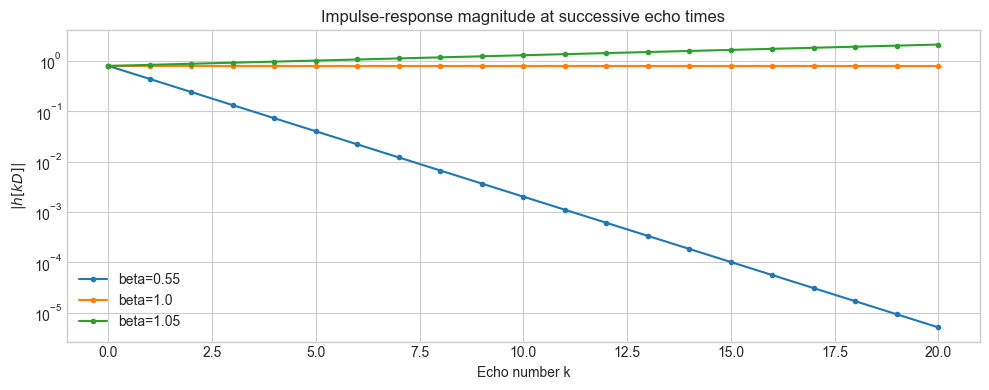

,beta,First echo magnitude,Echo 20 magnitude,BIBO stable
0,0.55,0.8,0.000005,True
1,1.00,0.8,0.800000,False
2,1.05,0.8,2.122638,False


In [6]:
echo_numbers = np.arange(21)
beta_values = [0.55, 1.0, 1.05]
stability_rows = []

fig, ax = plt.subplots(figsize=(10, 4))
for test_beta in beta_values:
    echo_magnitudes = alpha * np.abs(test_beta) ** echo_numbers
    stability_rows.append({
        "beta": test_beta,
        "First echo magnitude": echo_magnitudes[0],
        "Echo 20 magnitude": echo_magnitudes[-1],
        "BIBO stable": abs(test_beta) < 1,
    })
    ax.semilogy(echo_numbers, echo_magnitudes, marker="o", ms=3, label=f"beta={test_beta}")

ax.set(
    title="Impulse-response magnitude at successive echo times",
    xlabel="Echo number k",
    ylabel=r"$|h[kD]|$",
)
ax.legend()
fig.tight_layout()
plt.show()
display(pd.DataFrame(stability_rows).round(6))

### Result analysis

For (\beta=0.55), the echo magnitude falls from 0.8 to approximately (5.1\times10^{-6}) by echo 20, so its absolute sum converges. At (\beta=1), every echo remains at 0.8 and the absolute sum diverges. With (\beta=1.05), amplitudes grow and echo 20 reaches approximately 2.1226. The implementation is therefore BIBO-stable only for (|\beta|<1), or (0<\beta<1) under the assignment's positive-parameter convention.

### Code analysis

The plot evaluates the measured impulse-response law at successive delay times rather than plotting a running maximum. A logarithmic vertical axis clearly distinguishes geometric decay, constant amplitude, and geometric growth. The Boolean stability column applies the pole-magnitude criterion directly.

## 5. Parameter influence and FIR comparison

,beta,First feedback echo,Fourth feedback echo,Echoes to <1%,Time to <1% (s)
0,0.20,0.16,0.0013,3,0.54
1,0.55,0.44,0.0732,8,1.44
2,0.90,0.72,0.5249,44,7.92


,Filter,Delay (s),Echo behaviour,Output RMS,Peak magnitude,Stability
0,FIR (Task 1),0.12,one delayed copy,0.2789,1.3148,always stable
1,IIR (Task 2),0.18,repeated feedback echoes,0.2145,0.9553,|beta| < 1


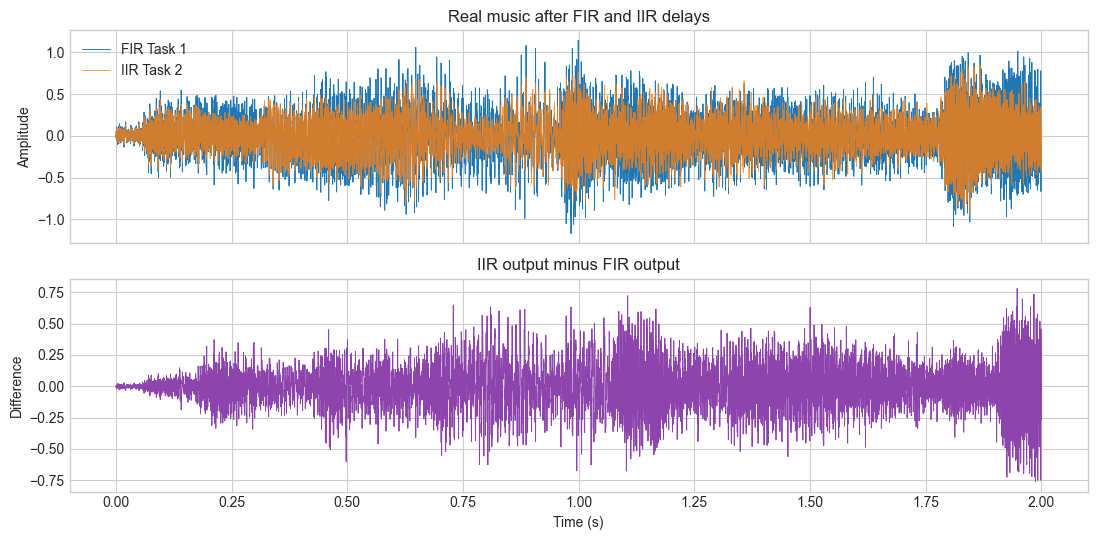

In [7]:
def fir_delay(input_signal, attenuation, delay):
    output = np.zeros_like(input_signal, dtype=float)
    for n, sample in enumerate(input_signal):
        output[n] = sample
        if n >= delay:
            output[n] += attenuation * input_signal[n - delay]
    return output


parameter_rows = []
for test_beta in [0.2, 0.55, 0.9]:
    echoes_to_one_percent = int(np.ceil(np.log(0.01) / np.log(test_beta)))
    parameter_rows.append({
        "beta": test_beta,
        "First feedback echo": alpha * test_beta,
        "Fourth feedback echo": alpha * test_beta**4,
        "Echoes to <1%": echoes_to_one_percent,
        "Time to <1% (s)": echoes_to_one_percent * delay_seconds,
    })
display(pd.DataFrame(parameter_rows).round(4))

fir_delay_samples = int(round(0.12 * sample_rate))
fir_output = fir_delay(audio, attenuation=0.65, delay=fir_delay_samples)
comparison = pd.DataFrame({
    "Filter": ["FIR (Task 1)", "IIR (Task 2)"],
    "Delay (s)": [0.12, delay_seconds],
    "Echo behaviour": ["one delayed copy", "repeated feedback echoes"],
    "Output RMS": [np.sqrt(np.mean(fir_output**2)), np.sqrt(np.mean(iir_output**2))],
    "Peak magnitude": [np.max(np.abs(fir_output)), np.max(np.abs(iir_output))],
    "Stability": ["always stable", "|beta| < 1"],
})
display(comparison.round(4))

view_end = int(2.0 * sample_rate)
fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
axes[0].plot(time[:view_end], fir_output[:view_end], lw=0.65, label="FIR Task 1")
axes[0].plot(time[:view_end], iir_output[:view_end], lw=0.65, alpha=0.8, label="IIR Task 2")
axes[0].set(title="Real music after FIR and IIR delays", ylabel="Amplitude")
axes[0].legend()
axes[1].plot(time[:view_end], iir_output[:view_end] - fir_output[:view_end], color="#8e44ad", lw=0.65)
axes[1].set(title="IIR output minus FIR output", xlabel="Time (s)", ylabel="Difference")
fig.tight_layout()
plt.show()

### Result analysis

Increasing (\alpha) scales the direct sound and every feedback echo. Increasing (\beta) extends the decay strongly: the response falls below 1% after 3 echoes for (\beta=0.2), 8 for 0.55, and 44 for 0.9. Increasing (D) increases the time between echoes and reduces the resonance spacing (f_s/D).

On `music.wav`, the Task 1 FIR setting produces RMS 0.2789 and peak 1.3148, whereas the Task 2 IIR setting produces RMS 0.2145 and peak 0.9553. The levels differ partly because the assignments use different direct-path definitions and chosen parameters. Structurally, the important distinction is that FIR creates one copy and is always stable, while IIR creates a decaying echo train only when (|\beta|<1).

### Code analysis

The beta table derives persistence from the impulse response using a reproducible 1% threshold. The comparison reuses the exact Task 1 parameters ((\alpha_{FIR}=0.65,D=0.12) s) and Task 2 parameters on the same loaded array. Reporting both RMS and peak prevents the waveform plot from being interpreted only qualitatively.